# Linear regression in diabetes dataset

Let's explore the datasets that are included in this Python library. These datasets have been cleaned and formatted for use in ML algorithms.

First, we will load the diabetes dataset. Do this in the cell below by importing the datasets and then loading the dataset  to the `diabetes` variable using the `load_diabetes()` function ([documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)).

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import pandas as pd
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()

In [4]:
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

Let's explore this variable by looking at the different attributes (keys) of `diabetes`. Note that the `load_diabetes` function does not return dataframes. It returns you a Python dictionary.

In [5]:
diabetes.keys()

dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])

#### The next step is to read the description of the dataset. 

Print the description in the cell below using the `DESCR` attribute of the `diabetes` variable. Read the data description carefully to fully understand what each column represents.

*Hint: If your output is ill-formatted by displaying linebreaks as `\n`, it means you are not using the `print` function.*

In [6]:
print(diabetes['DESCR'])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

#### Based on the data description, answer the following questions:

1. How many attributes are there in the data? What do they mean?

1. What is the relation between `diabetes['data']` and `diabetes['target']`?

1. How many records are there in the data?

10 attributes, are: edad, sexo, imc, tension arterial, colesterol, s2, s3, s4, s5, s6

la diferencia es que diabetes['data'] son los datos brutos del dataset, y diabetes['target'] son los datos objetivo con los que deseamos entrenar el modelo

442 registros, 422 para entrenar el modelo, y 20 pacientes que se apartan para test.

#### Now explore what are contained in the *data* portion as well as the *target* portion of `diabetes`. 

Scikit-learn typically takes in 2D numpy arrays as input (though pandas dataframes are also accepted). Inspect the shape of `data` and `target`. Confirm they are consistent with the data description.

In [29]:
X = pd.DataFrame(diabetes['data'], columns=diabetes['feature_names'])
y = pd.DataFrame(diabetes['target'], columns=['target'])

X.head()
X.info()
y.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   target  442 non-null    float64
dtypes: float64(1)
memory usage: 3.6 KB


In [30]:
y.shape

(442, 1)

In [33]:
dataframe_previo = pd.concat([X, y], axis=1)
dataframe_previo.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [34]:
dataframe_previo_definitivo_nofake = dataframe_previo.reset_index()



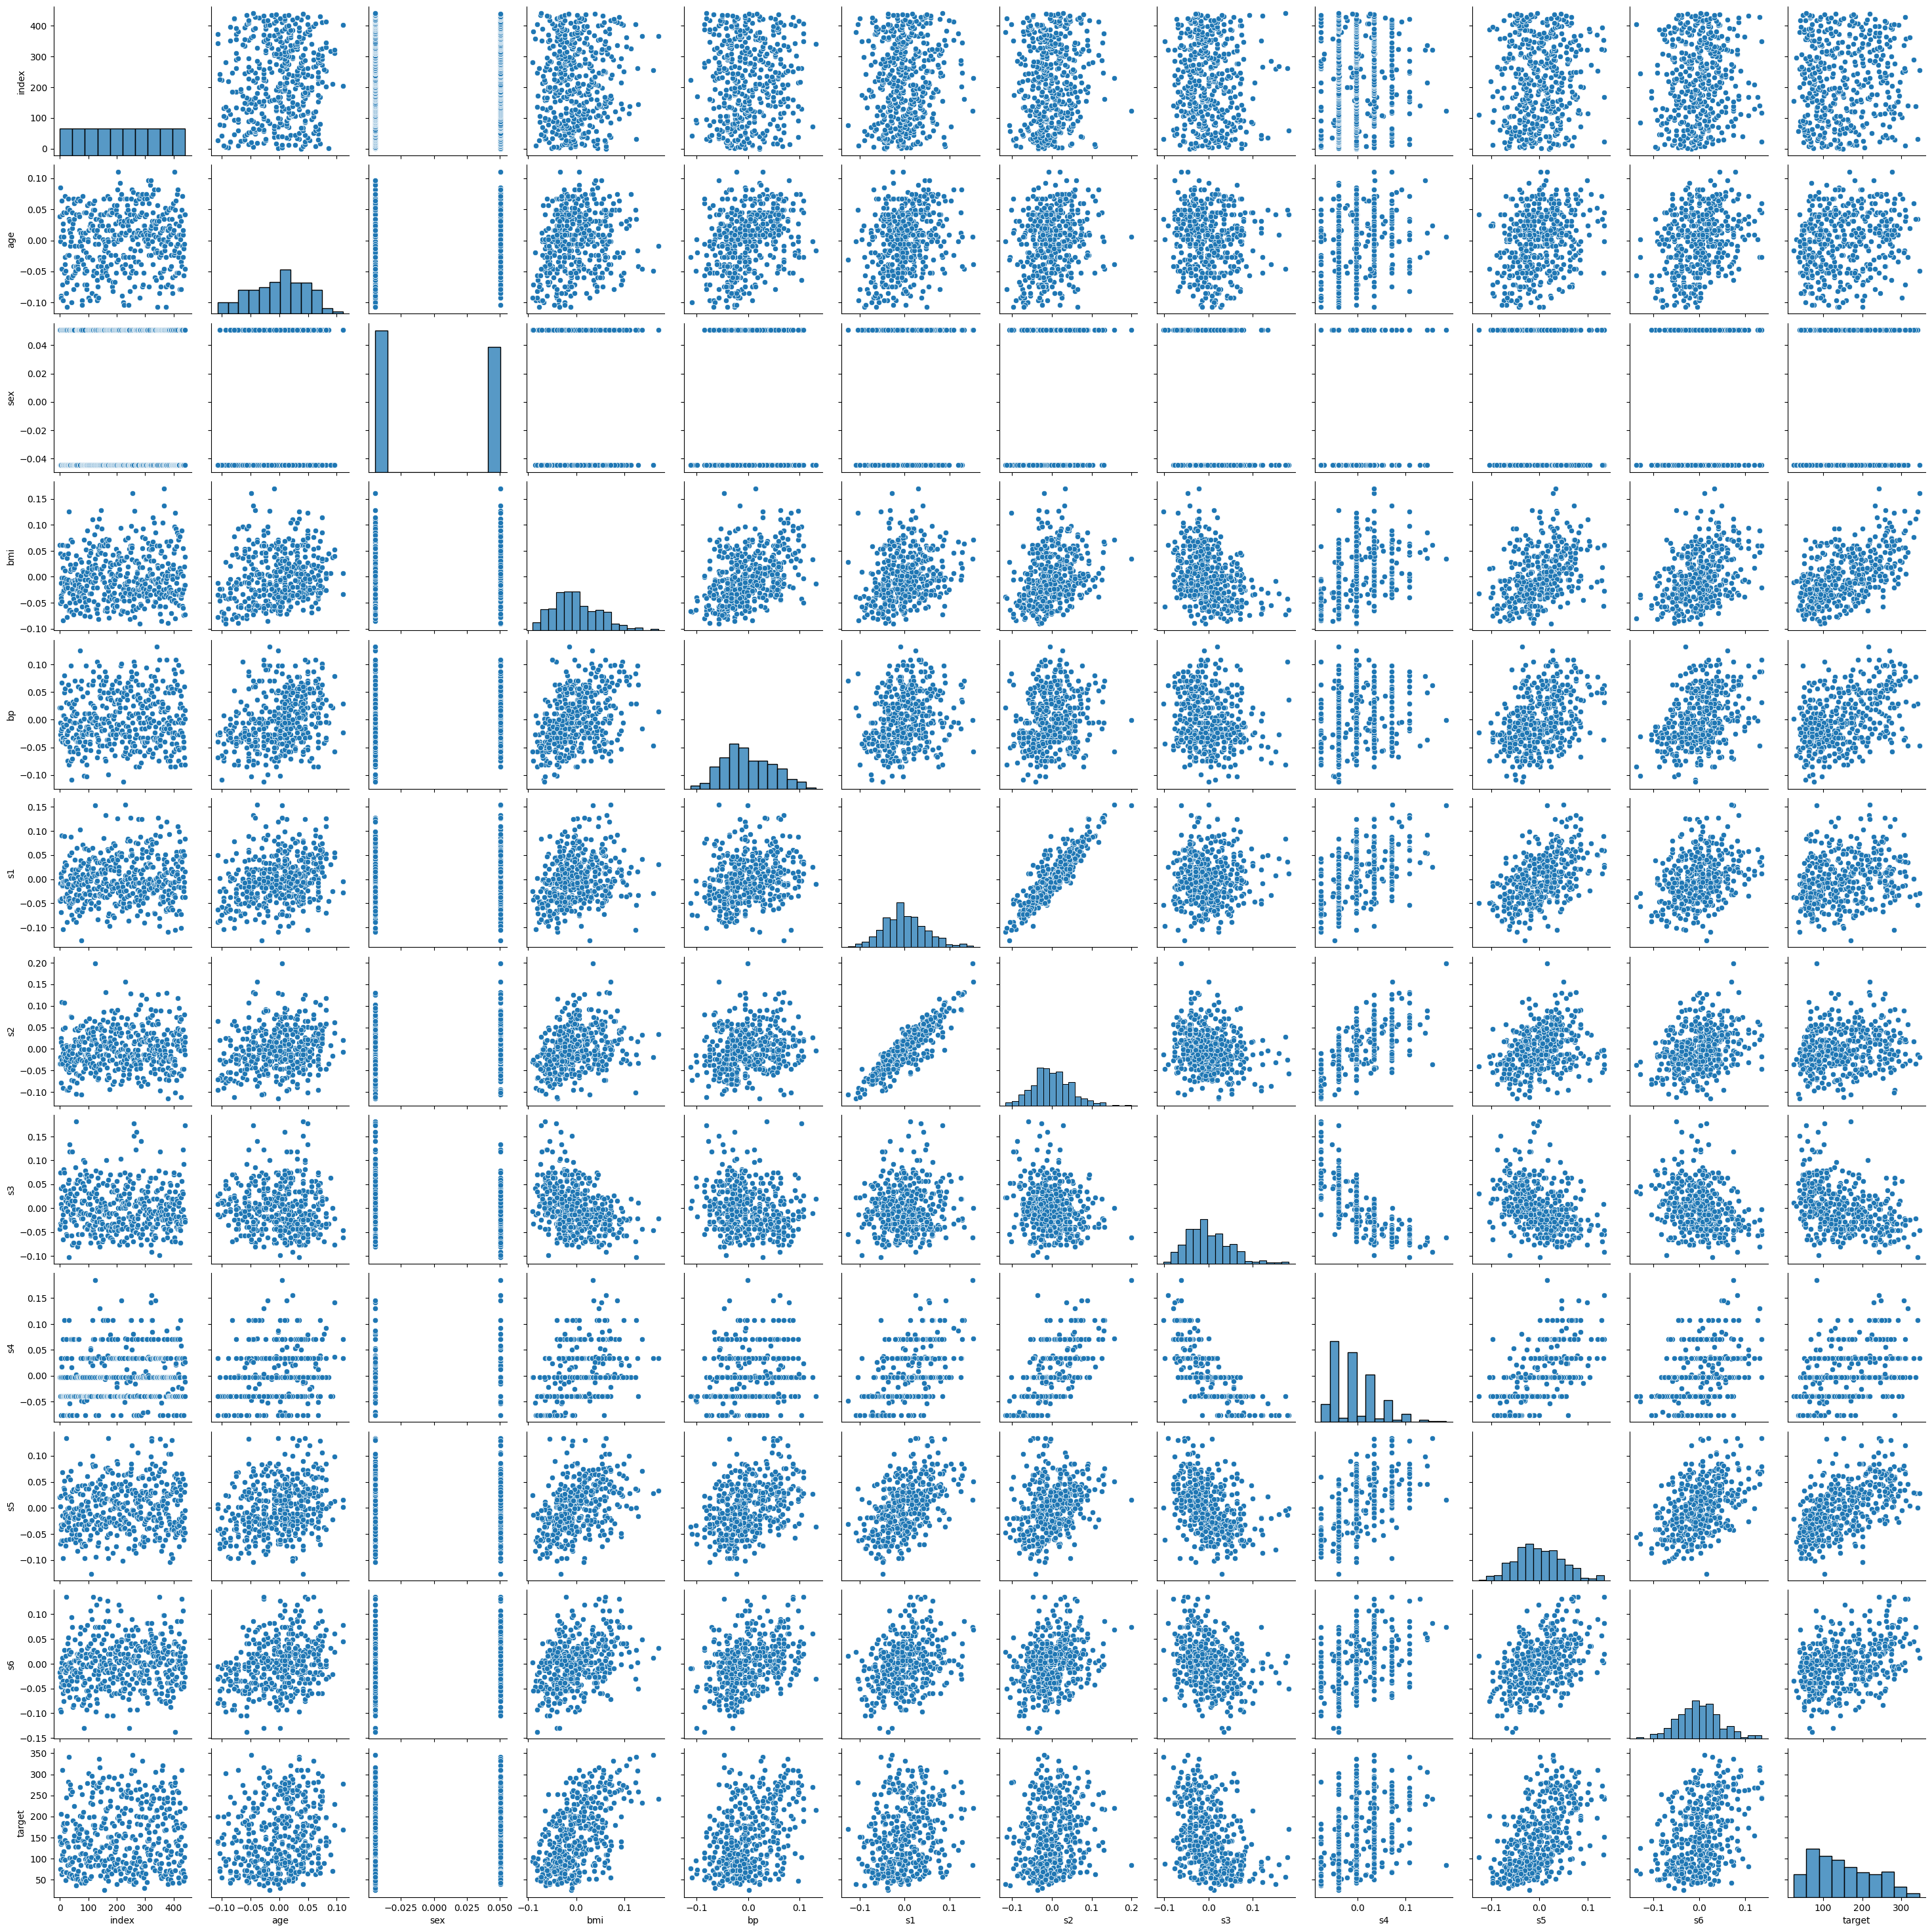

In [35]:
sns.pairplot(dataframe_previo_definitivo_nofake);

<Axes: >

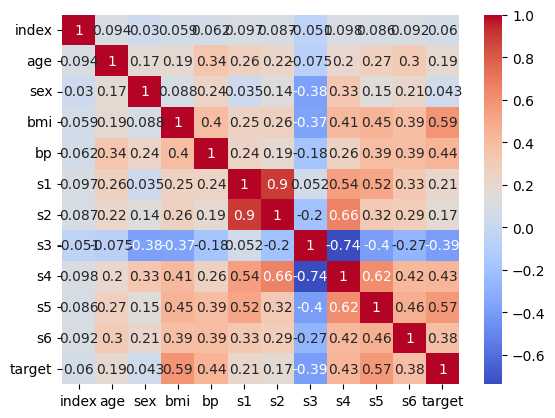

In [36]:
sns.heatmap(dataframe_previo_definitivo_nofake.corr(), annot=True, cmap='coolwarm')


## Building a regression model

In [24]:
pd.__version__

'3.0.1'

The data have already been split to predictor (*data*) and response (*target*) variables. Given this information, we'll apply what we have previously learned about linear regression and apply the algorithm to the diabetes dataset.

#### In the cell below, import the `linear_model` class from `sklearn`. 

In [40]:
from sklearn.linear_model import LinearRegression

#### Create a new instance of the linear regression model and assign the new instance to the variable `diabetes_model`.

In [41]:
diabetes_model = LinearRegression()

#### Next, let's split the training and test data.

Define `diabetes_data_train`, `diabetes_target_train`, `diabetes_data_test`, and `diabetes_target_test`. Use the last 20 records for the test data and the rest for the training data.

In [37]:

diabetes_data_test = X[-20:]
diabetes_data_train = X[ : -20]
diabetes_target_train = y[ : -20]
diabetes_target_test = y[-20 : ]

Perform a brief exploratory analysis to investigate the conditions necessary for linear regression. This analysis will help you understand the distribution of the target variable and its correlations with other features.

Fit the training data and target to `diabetes_model`. Print the *intercept* and *coefficients* of the model.

In [ ]:
entrenar = diabetes_model.fit(diabetes_data_train, diabetes_target_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [47]:
diabetes_model.intercept_

array([152.76429169])

In [48]:
diabetes_model.coef_

array([[ 3.06094248e-01, -2.37635570e+02,  5.10538048e+02,
         3.27729878e+02, -8.14111926e+02,  4.92799595e+02,
         1.02841240e+02,  1.84603496e+02,  7.43509388e+02,
         7.60966464e+01]])

#### Inspecting the results

From the outputs you should have seen:

- The intercept is a float number.
- The coefficients are an array containing 10 float numbers.

This is the linear regression model fitted to your training dataset.

#### Using your fitted linear regression model, predict the *y* of `diabetes_data_test`.

In [43]:
predecir = diabetes_model.predict(diabetes_data_test)

#### Print your `diabetes_target_test` and compare with the prediction. 

In [52]:
comparacion = pd.DataFrame(
 diabetes_target_test
)


In [53]:
comparacion.head()

,target
422,233.0
423,91.0
424,111.0
425,152.0
426,120.0


In [ ]:
comparacion['predicción'] = predecir


In [55]:
comparacion.head()

,target,predicción
422,233.0,197.618985
423,91.0,155.440320
424,111.0,172.888751
425,152.0,111.532706
426,120.0,164.793973


In [56]:

comparacion['Error'] = comparacion['target'] - comparacion['predicción']
comparacion



,target,predicción,Error
422,233.0,197.618985,35.381015
423,91.0,155.440320,-64.440320
424,111.0,172.888751,-61.888751
425,152.0,111.532706,40.467294
426,120.0,164.793973,-44.793973
427,67.0,131.067659,-64.067659
428,310.0,259.124412,50.875588
429,94.0,100.478737,-6.478737
430,183.0,117.060054,65.939946
431,66.0,124.302616,-58.302616


#### Is `diabetes_target_test` exactly the same as the model prediction? Use different error metrics

In [60]:
from sklearn import metrics
import numpy as np
print('MAE:', metrics.mean_absolute_error(diabetes_target_train, diabetes_model.predict(diabetes_data_train)))
print('MSE:', metrics.mean_squared_error(diabetes_target_train, diabetes_model.predict(diabetes_data_train)))
print('RMSE:', np.sqrt(metrics.mean_squared_error(diabetes_target_train, diabetes_model.predict(diabetes_data_train))))
print('R2:', metrics.r2_score(diabetes_target_train, diabetes_model.predict(diabetes_data_train)))

MAE: 43.61874785130125
MSE: 2901.566170402888
RMSE: 53.8661876356856
R2: 0.5122247821066493


In [ ]:

import numpy as np
print('MAE:', metrics.mean_absolute_error(diabetes_target_test, predecir))
print('MSE:', metrics.mean_squared_error(diabetes_target_test, predecir))
print('RMSE:', np.sqrt(metrics.mean_squared_error(diabetes_target_test, predecir)))
print('R2:', metrics.r2_score(diabetes_target_test, predecir))

MAE: 36.60961865545878
MSE: 2004.5186863342085
RMSE: 44.77185149548998
R2: 0.5850854274471953


#### Iterate with a new model to assess if any improvements can be made compared to the previous one. Consider reducing the number of variables or using `StandardScaler` to enhance model performance.

In [22]:
from sklearn import preprocessing

diabetes_scale = preprocessing.StandardScaler()
diabetes_scale.fit(diabetes_data_train)
X_Train_scale = diabetes_scale.transform(diabetes_data_train)
X_Test_scale = diabetes_scale.transform(diabetes_data_test)
diabetes_model_2 = LinearRegression()
diabetes_model_2.fit(X_Train_scale, diabetes_target_train)
predecir_2 = diabetes_model_2.predict(X_Test_scale)
intercept_scal = diabetes_model_2.intercept_

print('MAE:', metrics.mean_absolute_error(diabetes_target_test, predecir_2))
print('RMSE:', np.sqrt(metrics.mean_squared_error(diabetes_target_test, predecir_2)))
print('R2:', metrics.r2_score(diabetes_target_test, predecir_2))

pd.DataFrame(diabetes_model_2.coef_, X.columns, columns=['coeficiente']).sort_values('coeficiente')



MAE: 36.60961865545879
RMSE: 44.77185149549
R2: 0.585085427447195


,coeficiente
s1,-38.634072
sex,-11.300962
age,0.014631
s6,3.606619
s3,4.817996
s4,8.799364
bp,15.598870
s2,23.384473
bmi,24.295677
s5,35.644497
